<a href="https://colab.research.google.com/github/IchiroBanskota/Bot-Detection/blob/master/Bot_Detection-2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Compare models

In [42]:
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [43]:
import kagglehub
import pandas as pd
import os

# Download or locate the cached dataset
path = kagglehub.dataset_download(
    "danieltreiman/twitter-human-bots-dataset"
)

print("Dataset location:", path)
print("Files:", os.listdir(path))

# Load dataset
df = pd.read_csv(
    os.path.join(path, "twitter_human_bots_dataset.csv")
)

# Display first 5 rows
display(df.head())

print("Dataset shape:", df.shape)

# Remove columns not used in your baseline
columns_to_drop = [
    "Unnamed: 0",
    "created_at",
    "description",
    "id",
    "lang",
    "location",
    "profile_background_image_url",
    "profile_image_url",
    "screen_name",
    "profile_image_path",
    "profile_background_image_path",
    "split"
]

df = df.drop(columns=columns_to_drop)

# Remove missing values and duplicates
df = df.dropna()
df = df.drop_duplicates()

# Convert boolean features to integers
boolean_columns = [
    "default_profile",
    "default_profile_image",
    "geo_enabled",
    "verified"
]

df[boolean_columns] = df[boolean_columns].astype(int)

# Convert labels
df["account_type"] = (
    df["account_type"] == "bot"
).astype(int)

# Features and target
X = df.drop(columns=["account_type"])
y = df["account_type"]

print("Features:", X.columns.tolist())
print("Dataset shape:", X.shape)

Using Colab cache for faster access to the 'twitter-human-bots-dataset' dataset.
Dataset location: /kaggle/input/twitter-human-bots-dataset
Files: ['twitter_human_bots_dataset.csv', 'profile_images', 'profile_background_images']


,Unnamed: 0,created_at,default_profile,default_profile_image,description,favourites_count,followers_count,friends_count,geo_enabled,id,...,profile_image_url,screen_name,statuses_count,verified,average_tweets_per_day,account_age_days,account_type,profile_image_path,profile_background_image_path,split
0,0,2009-07-04 22:41:51,False,False,NaN,5007,102,168,False,53779179,...,https://pbs.twimg.com/profile_images/128969130...,paty_castroo,3974,False,0.978,4063,bot,NaN,NaN,0
1,1,2010-01-17 22:54:19,False,False,Television producer. Emmy Award winner. Disney...,1038,60,128,False,105916557,...,https://pbs.twimg.com/profile_images/632916759...,CBirckner,259,False,0.067,3866,human,profile_images/4691ae58668d932bb7e7af22141aecf...,profile_images/4691ae58668d932bb7e7af22141aecf...,0
2,2,2012-03-01 06:05:32,False,False,NaN,2257,599,449,True,509788597,...,https://pbs.twimg.com/profile_images/128853844...,amf_jay,13627,False,4.406,3093,human,NaN,NaN,0
3,3,2009-09-01 04:52:30,False,False,NaN,6407,116,334,True,70601327,...,https://pbs.twimg.com/profile_images/977012905...,SaraCavolo,4432,False,1.107,4005,human,profile_images/d1da9220e4aa376dff03b6f12765171...,profile_images/d1da9220e4aa376dff03b6f12765171...,0
4,4,2010-01-27 17:17:23,False,False,Productor de Televisión - Embajador de @Tienda...,20866,74448,18,True,108999927,...,https://pbs.twimg.com/profile_images/668449819...,DavidHenaoModel,15870,True,4.116,3856,human,profile_images/c65bf625b066ef5f29e14cfcf1ee91f...,profile_images/c65bf625b066ef5f29e14cfcf1ee91f...,0


Dataset shape: (37438, 23)
Features: ['default_profile', 'default_profile_image', 'favourites_count', 'followers_count', 'friends_count', 'geo_enabled', 'statuses_count', 'verified', 'average_tweets_per_day', 'account_age_days']
Dataset shape: (37404, 10)


In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [45]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        random_state=42
    ),

    "Neural Network (MLP)": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=500,
            random_state=42
        )
    )
}

In [46]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        }
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Bot Recall": scores["test_recall"].mean(),
        "Bot F1": scores["test_f1"].mean()
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Bot F1",
        ascending=False
    )
)

,Model,Accuracy,Precision,Bot Recall,Bot F1
3,Gradient Boosting,0.880059,0.857996,0.764848,0.808709
2,Random Forest,0.880326,0.862998,0.759605,0.807967
1,Decision Tree,0.826588,0.734959,0.745790,0.740320
4,Neural Network (MLP),0.830465,0.772508,0.694862,0.730439
0,Logistic Regression,0.757745,0.654006,0.571443,0.609916


In [47]:
# Select best model using CV F1
best_name = results_df.loc[
    results_df["Bot F1"].idxmax(),
    "Model"
]

best_model = models[best_name]

# Train on the entire training set
best_model.fit(X_train, y_train)

# Evaluate on untouched test data
y_pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

display(
    results_df.sort_values(
        by="Bot F1",
        ascending=False
    ).round(4)
)

Best model: Gradient Boosting
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      5002
           1       0.84      0.76      0.80      2479

    accuracy                           0.87      7481
   macro avg       0.87      0.85      0.85      7481
weighted avg       0.87      0.87      0.87      7481

Confusion matrix:
[[4651  351]
 [ 590 1889]]


,Model,Accuracy,Precision,Bot Recall,Bot F1
3,Gradient Boosting,0.8801,0.8580,0.7648,0.8087
2,Random Forest,0.8803,0.8630,0.7596,0.8080
1,Decision Tree,0.8266,0.7350,0.7458,0.7403
4,Neural Network (MLP),0.8305,0.7725,0.6949,0.7304
0,Logistic Regression,0.7577,0.6540,0.5714,0.6099


## SHAP

In [49]:
# TWITTER BOT DETECTION — SHAP EXPLAINABILITY

%pip -q install kagglehub shap

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import shap

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [50]:
# Load dataset

path = kagglehub.dataset_download(
    "danieltreiman/twitter-human-bots-dataset"
)

df = pd.read_csv(
    os.path.join(path, "twitter_human_bots_dataset.csv")
)

print("Original dataset shape:", df.shape)

df.head()

Using Colab cache for faster access to the 'twitter-human-bots-dataset' dataset.
Original dataset shape: (37438, 23)


,Unnamed: 0,created_at,default_profile,default_profile_image,description,favourites_count,followers_count,friends_count,geo_enabled,id,...,profile_image_url,screen_name,statuses_count,verified,average_tweets_per_day,account_age_days,account_type,profile_image_path,profile_background_image_path,split
0,0,2009-07-04 22:41:51,False,False,NaN,5007,102,168,False,53779179,...,https://pbs.twimg.com/profile_images/128969130...,paty_castroo,3974,False,0.978,4063,bot,NaN,NaN,0
1,1,2010-01-17 22:54:19,False,False,Television producer. Emmy Award winner. Disney...,1038,60,128,False,105916557,...,https://pbs.twimg.com/profile_images/632916759...,CBirckner,259,False,0.067,3866,human,profile_images/4691ae58668d932bb7e7af22141aecf...,profile_images/4691ae58668d932bb7e7af22141aecf...,0
2,2,2012-03-01 06:05:32,False,False,NaN,2257,599,449,True,509788597,...,https://pbs.twimg.com/profile_images/128853844...,amf_jay,13627,False,4.406,3093,human,NaN,NaN,0
3,3,2009-09-01 04:52:30,False,False,NaN,6407,116,334,True,70601327,...,https://pbs.twimg.com/profile_images/977012905...,SaraCavolo,4432,False,1.107,4005,human,profile_images/d1da9220e4aa376dff03b6f12765171...,profile_images/d1da9220e4aa376dff03b6f12765171...,0
4,4,2010-01-27 17:17:23,False,False,Productor de Televisión - Embajador de @Tienda...,20866,74448,18,True,108999927,...,https://pbs.twimg.com/profile_images/668449819...,DavidHenaoModel,15870,True,4.116,3856,human,profile_images/c65bf625b066ef5f29e14cfcf1ee91f...,profile_images/c65bf625b066ef5f29e14cfcf1ee91f...,0


In [51]:
# Clean data

df["account_type"] = (
    df["account_type"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"human": 0, "bot": 1})
)

df = df.dropna(subset=["account_type", "split"])
df = df.drop_duplicates(subset=["id"]).copy()

df["account_type"] = df["account_type"].astype(int)
df["split"] = pd.to_numeric(df["split"], errors="coerce")

df = df[df["split"].isin([0, 1, 2])].reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

print("\nAccount type distribution:")
print(df["account_type"].value_counts())

print("\nDataset split distribution:")
print(df["split"].value_counts())

Cleaned dataset shape: (37438, 23)

Account type distribution:
account_type
0    25013
1    12425
Name: count, dtype: int64

Dataset split distribution:
split
0    29950
2     3745
1     3743
Name: count, dtype: int64


In [52]:
# Select original features

original_features = [
    "default_profile",
    "default_profile_image",
    "favourites_count",
    "followers_count",
    "friends_count",
    "geo_enabled",
    "statuses_count",
    "verified",
    "average_tweets_per_day",
    "account_age_days"
]

for col in original_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Original features selected:", len(original_features))

Original features selected: 10


In [53]:
# Feature engineering

# Follower-to-following ratio
df["follower_following_ratio"] = (
    df["followers_count"] / (df["friends_count"] + 1)
)

# Tweets per follower
df["tweets_per_follower"] = (
    df["statuses_count"] / (df["followers_count"] + 1)
)

# Likes per tweet
df["likes_per_tweet"] = (
    df["favourites_count"] / (df["statuses_count"] + 1)
)

# Biography features
df["bio_length"] = (
    df["description"].fillna("").astype(str).str.len()
)

df["has_bio"] = (
    df["description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
    .astype(int)
)

# Username features
df["username_length"] = (
    df["screen_name"].fillna("").astype(str).str.len()
)

df["username_digit_count"] = (
    df["screen_name"]
    .fillna("")
    .astype(str)
    .apply(lambda s: sum(c.isdigit() for c in s))
)

df["username_digit_ratio"] = (
    df["username_digit_count"]
    / df["username_length"].clip(lower=1)
)

# Log-transformed features
df["log_followers"] = np.log1p(
    df["followers_count"].clip(lower=0)
)

df["log_statuses"] = np.log1p(
    df["statuses_count"].clip(lower=0)
)

engineered_features = [
    "follower_following_ratio",
    "tweets_per_follower",
    "likes_per_tweet",
    "bio_length",
    "has_bio",
    "username_length",
    "username_digit_count",
    "username_digit_ratio",
    "log_followers",
    "log_statuses"
]

print("Engineered features created:", len(engineered_features))

Engineered features created: 10


In [54]:
# Prepare feature matrix

features = original_features + engineered_features

X = df[features].replace(
    [np.inf, -np.inf], np.nan
)

y = df["account_type"]

print("Number of original features:", len(original_features))
print("Number of engineered features:", len(engineered_features))
print("Total number of features:", len(features))

print("\nFeature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

Number of original features: 10
Number of engineered features: 10
Total number of features: 20

Feature matrix shape: (37438, 20)
Target variable shape: (37438,)


In [55]:
# Use predefined dataset splits

train_mask = df["split"] == 0
valid_mask = df["split"] == 1
test_mask = df["split"] == 2

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_valid = X.loc[valid_mask]
y_valid = y.loc[valid_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Training accounts:", len(X_train))
print("Validation accounts:", len(X_valid))
print("Testing accounts:", len(X_test))

Training accounts: 29950
Validation accounts: 3743
Testing accounts: 3745


In [56]:
# Train Random Forest model

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [57]:
# Evaluate validation performance

y_pred = model.predict(X_valid)

print("\n========== VALIDATION RESULTS ==========")

print("Accuracy:", round(
    accuracy_score(y_valid, y_pred), 4
))

print("Bot Precision:", round(
    precision_score(y_valid, y_pred, zero_division=0), 4
))

print("Bot Recall:", round(
    recall_score(y_valid, y_pred, zero_division=0), 4
))

print("Bot F1:", round(
    f1_score(y_valid, y_pred, zero_division=0), 4
))

print("\nClassification Report:")

print(classification_report(
    y_valid,
    y_pred,
    target_names=["Human", "Bot"],
    zero_division=0
))


========== VALIDATION RESULTS ==========
Accuracy: 0.883
Bot Precision: 0.8899
Bot Recall: 0.7466
Bot F1: 0.812

Classification Report:
              precision    recall  f1-score   support

       Human       0.88      0.95      0.92      2476
         Bot       0.89      0.75      0.81      1267

    accuracy                           0.88      3743
   macro avg       0.89      0.85      0.86      3743
weighted avg       0.88      0.88      0.88      3743



In [58]:
# Prepare data for SHAP

# Sample validation accounts not seen during training
X_shap = X_valid.sample(
    n=min(300, len(X_valid)),
    random_state=42
)

# Extract trained imputer and Random Forest
imputer = model.named_steps["imputer"]
forest = model.named_steps["model"]

# Apply imputation
X_processed = pd.DataFrame(
    imputer.transform(X_shap),
    columns=features,
    index=X_shap.index
)

print("SHAP dataset shape:", X_processed.shape)
print("Preparing to compute SHAP values...")

SHAP dataset shape: (300, 20)
Preparing to compute SHAP values...


In [59]:
# Compute SHAP values

explainer = shap.TreeExplainer(forest)

shap_values = explainer(X_processed)

# For a binary Random Forest, recent SHAP versions
# return one explanation per class.
# Class 1 = Bot.

if shap_values.values.ndim == 3:
    bot_shap = shap_values[:, :, 1]
else:
    bot_shap = shap_values

print("SHAP computation completed.")

SHAP computation completed.


SHAP BEESWARM PLOT


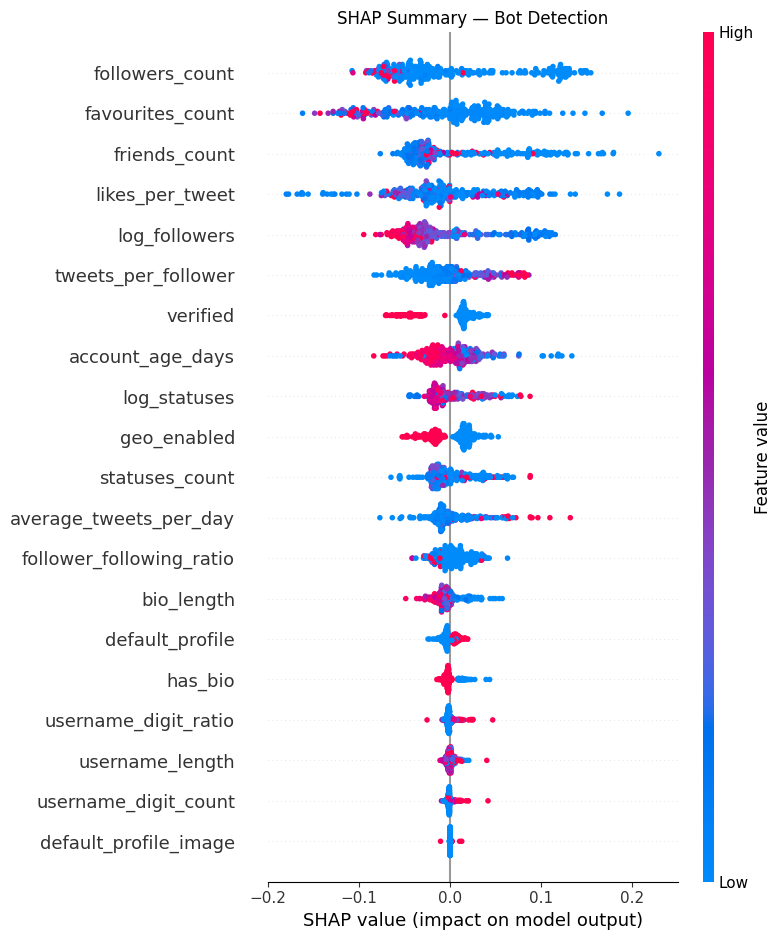

In [60]:
# SHAP beeswarm plot

print("SHAP BEESWARM PLOT")

shap.plots.beeswarm(
    bot_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Summary — Bot Detection")
plt.tight_layout()
plt.show()


SHAP WATERFALL PLOT
Actual class: 1
Predicted class: 1
Predicted bot probability: 1.0


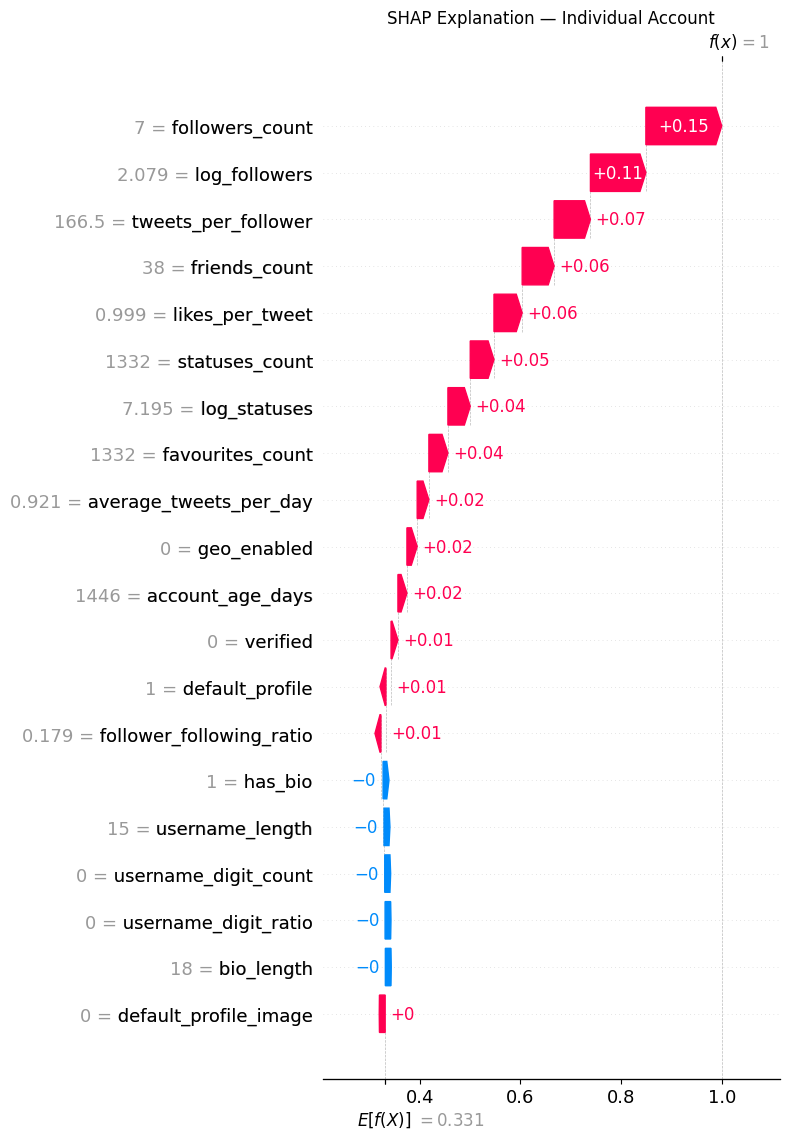

In [61]:
# Explain an individual bot prediction

predictions = model.predict(X_shap)

# Prefer an account predicted as a bot
bot_indices = np.where(predictions == 1)[0]

if len(bot_indices) > 0:
    example_idx = int(bot_indices[0])
else:
    example_idx = 0

print("\nSHAP WATERFALL PLOT")

print(
    "Actual class:",
    int(y_valid.loc[X_shap.index[example_idx]])
)

print(
    "Predicted class:",
    int(predictions[example_idx])
)

print(
    "Predicted bot probability:",
    round(
        float(model.predict_proba(
            X_shap.iloc[[example_idx]]
        )[0, 1]),
        4
    )
)

shap.plots.waterfall(
    bot_shap[example_idx],
    max_display=20,
    show=False
)

plt.title("SHAP Explanation — Individual Account")
plt.tight_layout()
plt.show()

In [62]:
# Save SHAP feature importance

importance = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": np.abs(
        bot_shap.values
    ).mean(axis=0)
})

importance = importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

print("\n========== SHAP FEATURE RANKING ==========")

print(importance.to_string(index=False))

importance.to_csv(
    "shap_feature_importance.csv",
    index=False
)

print("\nSaved: shap_feature_importance.csv")

print("\nSHAP EXPLAINABILITY EXPERIMENT COMPLETE")


========== SHAP FEATURE RANKING ==========
                 Feature  Mean_Absolute_SHAP
         followers_count            0.058860
        favourites_count            0.050085
           friends_count            0.048056
         likes_per_tweet            0.044746
           log_followers            0.044279
     tweets_per_follower            0.027153
                verified            0.024838
        account_age_days            0.023950
            log_statuses            0.019850
             geo_enabled            0.019757
          statuses_count            0.018912
  average_tweets_per_day            0.018313
follower_following_ratio            0.013460
              bio_length            0.011056
         default_profile            0.005774
                 has_bio            0.005241
    username_digit_ratio            0.003284
         username_length            0.003065
    username_digit_count            0.002598
   default_profile_image            0.000288

Saved: sha

extra

In [63]:
import pandas as pd
import kagglehub
import os

# Load the cached dataset
path = kagglehub.dataset_download(
    "danieltreiman/twitter-human-bots-dataset"
)

df = pd.read_csv(
    os.path.join(path, "twitter_human_bots_dataset.csv")
)

# Check split values
print("Unique split values:")
print(df["split"].unique())

print("\nNumber of accounts in each split:")
print(df["split"].value_counts(dropna=False))

print("\nBot and human counts in each split:")
print(pd.crosstab(df["split"], df["account_type"]))

Using Colab cache for faster access to the 'twitter-human-bots-dataset' dataset.
Unique split values:
[0 1 2]

Number of accounts in each split:
split
0    29950
2     3745
1     3743
Name: count, dtype: int64

Bot and human counts in each split:
account_type   bot  human
split                    
0             9932  20018
1             1267   2476
2             1226   2519


In [64]:
import os

print("Dataset folder:", path)

print("\nTop-level files and folders:")
print(os.listdir(path)[:30])

print("\nNon-null profile image paths:")
print(df["profile_image_path"].notna().sum())

print("\nNon-null background image paths:")
print(df["profile_background_image_path"].notna().sum())

print("\nExample profile image paths:")
print(df["profile_image_path"].dropna().head(5).tolist())

# Check whether referenced images actually exist
sample_paths = df["profile_image_path"].dropna().head(10)

for relative_path in sample_paths:
    full_path = os.path.join(path, str(relative_path))
    print(os.path.isfile(full_path), full_path)

Dataset folder: /kaggle/input/twitter-human-bots-dataset

Top-level files and folders:
['twitter_human_bots_dataset.csv', 'profile_images', 'profile_background_images']

Non-null profile image paths:
24500

Non-null background image paths:
24500

Example profile image paths:
['profile_images/4691ae58668d932bb7e7af22141aecfc8f159764.jpg', 'profile_images/d1da9220e4aa376dff03b6f127651713b71fbc4e.jpg', 'profile_images/c65bf625b066ef5f29e14cfcf1ee91fea680df47.jpg', 'profile_images/848c190606cd415153938b4e45ec83fef4544fd0.jpg', 'profile_images/4a020d1683687ab89250f76b06895ed06ac7af74.jpg']
True /kaggle/input/twitter-human-bots-dataset/profile_images/4691ae58668d932bb7e7af22141aecfc8f159764.jpg
True /kaggle/input/twitter-human-bots-dataset/profile_images/d1da9220e4aa376dff03b6f127651713b71fbc4e.jpg
True /kaggle/input/twitter-human-bots-dataset/profile_images/c65bf625b066ef5f29e14cfcf1ee91fea680df47.jpg
True /kaggle/input/twitter-human-bots-dataset/profile_images/848c190606cd415153938b4e45ec8